In [1]:
print("Oasis Infobyte - Retail Sales EDA")
print("My Python setup is ready!")

Oasis Infobyte - Retail Sales EDA
My Python setup is ready!


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("retail_sales_dataset.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Number of rows and columns: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("retail_sales_dataset.csv")

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

df.head()

Dataset loaded successfully!
Number of rows and columns: (1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:

# Display all column names
print("Column Names:")
print(df.columns.tolist())

# Check dataset information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Statistical summary
print("\nStatistical Summary:")
df.describe()


Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price 

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [4]:

# Convert Date column into datetime format
df["Date"] = pd.to_datetime(df["Date"])

# Check updated data types
print("Updated Data Types:")
print(df.dtypes)

# Calculate average, median and mode
print("\nMean of numerical columns:")
print(df.mean(numeric_only=True))

print("\nMedian of numerical columns:")
print(df.median(numeric_only=True))

print("\nMode of numerical columns:")
print(df.mode(numeric_only=True).iloc[0])

print("\nStandard Deviation:")
print(df.std(numeric_only=True))


Updated Data Types:
Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

Mean of numerical columns:
Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

Median of numerical columns:
Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

Mode of numerical columns:
Transaction ID     1.0
Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64

Standard Deviation:
Transaction ID    288.819436
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amo

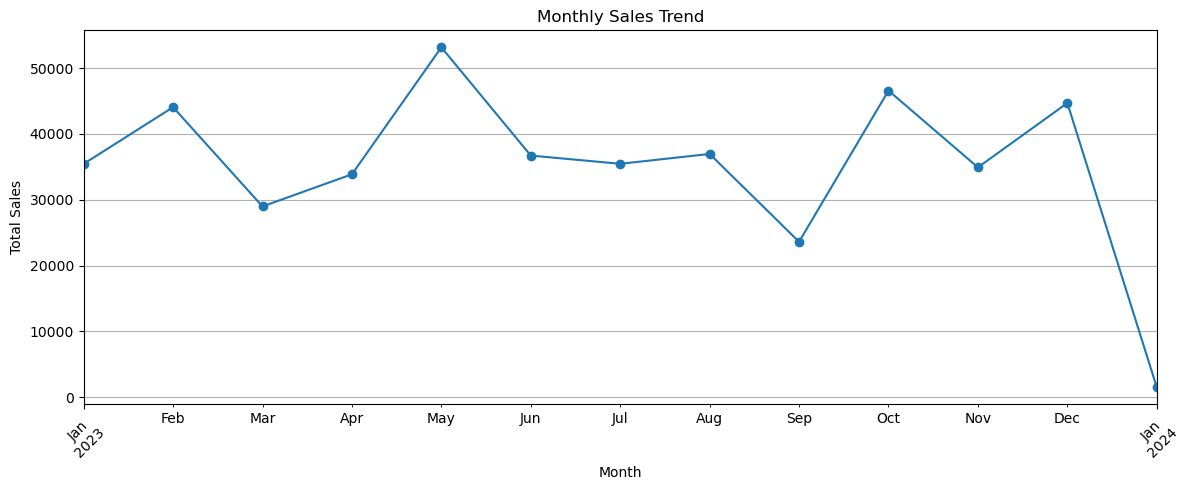

In [5]:

# Monthly Sales Trend

df["Month"] = df["Date"].dt.to_period("M")

monthly_sales = df.groupby("Month")["Total Amount"].sum()

plt.figure(figsize=(12, 5))
monthly_sales.plot(marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


### Observation
The monthly sales trend helps identify changes in sales over time. Months with higher sales indicate stronger business performance, while months with lower sales may require further investigation.


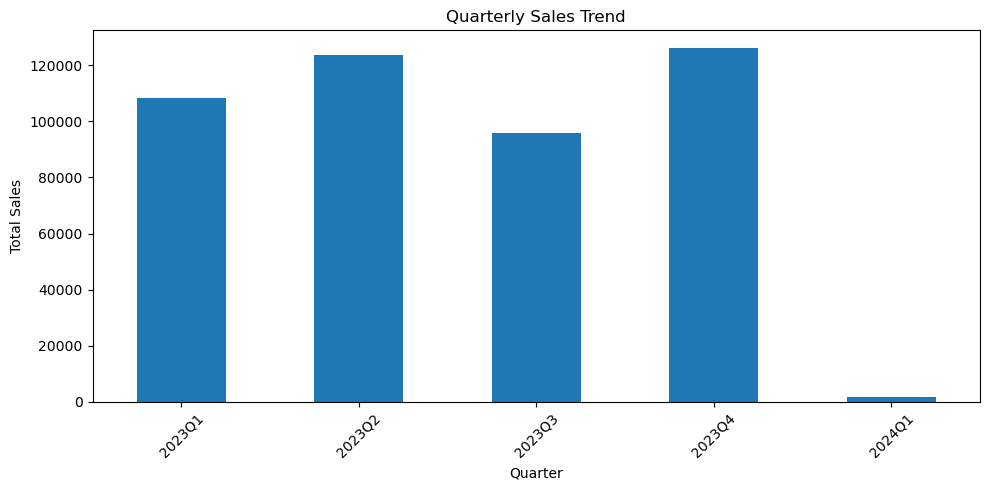

In [6]:

# Quarterly Sales Trend

df["Quarter"] = df["Date"].dt.to_period("Q")

quarterly_sales = df.groupby("Quarter")["Total Amount"].sum()

plt.figure(figsize=(10, 5))
quarterly_sales.plot(kind="bar")

plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Observation
The quarterly sales chart compares total sales across three-month periods. The highest-sales quarter represents the strongest sales period, while the lowest-sales quarter may need further investigation.

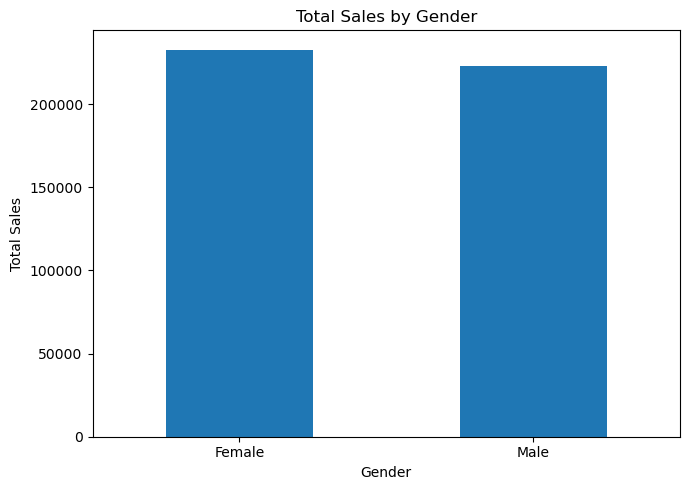

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64


In [7]:

# Sales by Gender

gender_sales = df.groupby("Gender")["Total Amount"].sum()

plt.figure(figsize=(7, 5))
gender_sales.plot(kind="bar")

plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(gender_sales)



# Sales by Gender

gender_sales = df.groupby("Gender")["Total Amount"].sum()

plt.figure(figsize=(7, 5))
gender_sales.plot(kind="bar")

plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(gender_sales)


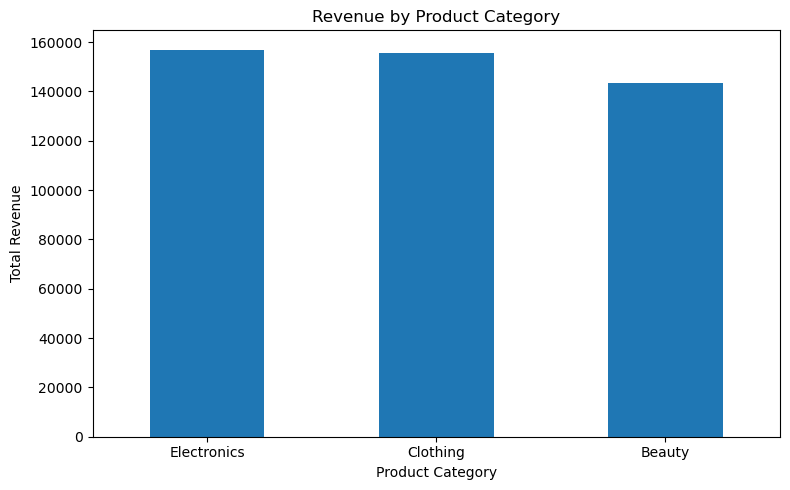

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64


In [8]:

# Revenue by Product Category

category_sales = df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
category_sales.plot(kind="bar")

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(category_sales)


### Observation
The category-wise revenue chart identifies which product categories generate the most and least revenue. The business can use this comparison to plan inventory, promotions and category-specific marketing.

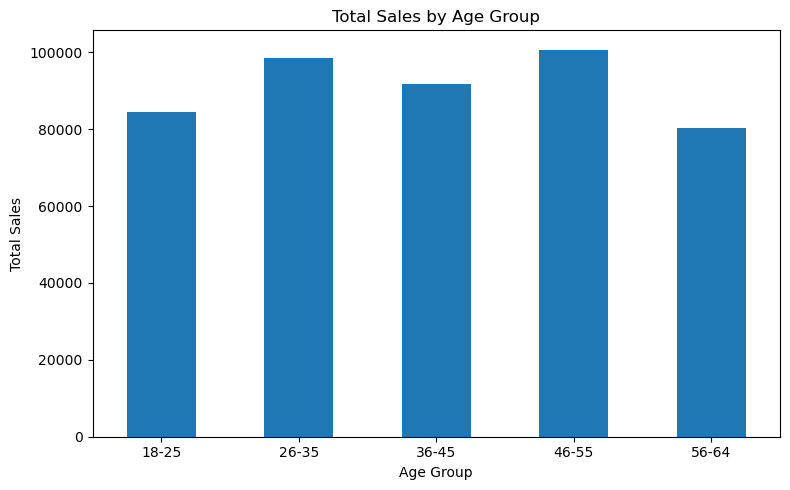

Age Group
18-25     84550
26-35     98480
36-45     91870
46-55    100690
56-64     80410
Name: Total Amount, dtype: int64


In [9]:
df["Age Group"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=["18-25", "26-35", "36-45", "46-55", "56-64"]
)

age_sales = df.groupby("Age Group", observed=False)["Total Amount"].sum()

plt.figure(figsize=(8, 5))
age_sales.plot(kind="bar")
plt.title("Total Sales by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(age_sales)

**Observation: Age Group Analysis**

The age group analysis compares total sales generated by customers from different age groups. The age group with the highest sales contributes the most revenue in this dataset. This information can help the business plan targeted marketing campaigns for different age groups.

In [10]:
top_transactions = df.nlargest(10, "Total Amount")[
    ["Transaction ID", "Customer ID", "Product Category", "Total Amount"]
]

print("Top 10 Transactions by Sales:")
display(top_transactions)

Top 10 Transactions by Sales:


,Transaction ID,Customer ID,Product Category,Total Amount
14,15,CUST015,Electronics,2000
64,65,CUST065,Electronics,2000
71,72,CUST072,Electronics,2000
73,74,CUST074,Beauty,2000
88,89,CUST089,Electronics,2000
92,93,CUST093,Beauty,2000
108,109,CUST109,Electronics,2000
117,118,CUST118,Electronics,2000
123,124,CUST124,Clothing,2000
138,139,CUST139,Beauty,2000


**Observation: Top 10 Transactions by Sales**

This analysis identifies the ten transactions with the highest total amounts. These transactions help highlight high-value purchases and customer spending patterns. The business can study these transactions to understand purchasing behaviour and develop strategies to encourage higher-value purchases.

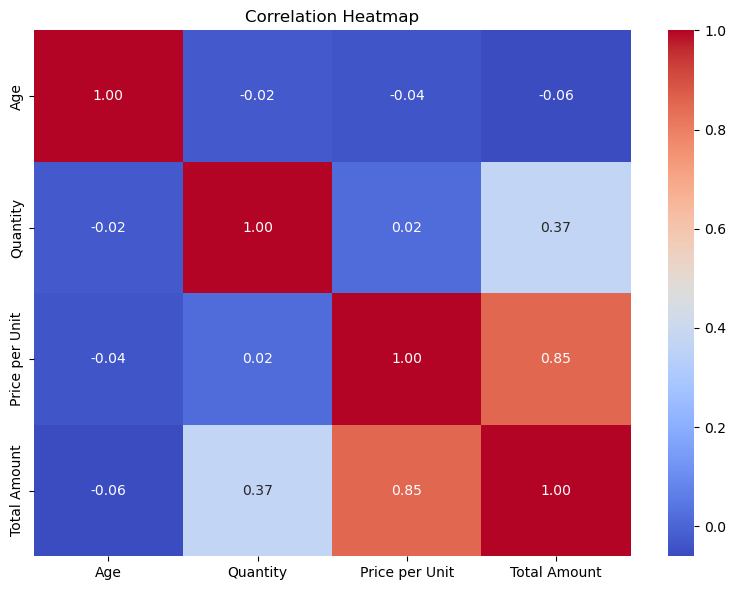

In [11]:
numeric_data = df[["Age", "Quantity", "Price per Unit", "Total Amount"]]

correlation = numeric_data.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

**Observation: Correlation Heatmap**

The correlation heatmap shows the relationship between numerical variables in the retail sales dataset. Values close to +1 indicate a strong positive relationship, values close to -1 indicate a strong negative relationship, and values close to 0 indicate a weak linear relationship. This analysis helps understand how variables such as quantity, price per unit and total amount are related.

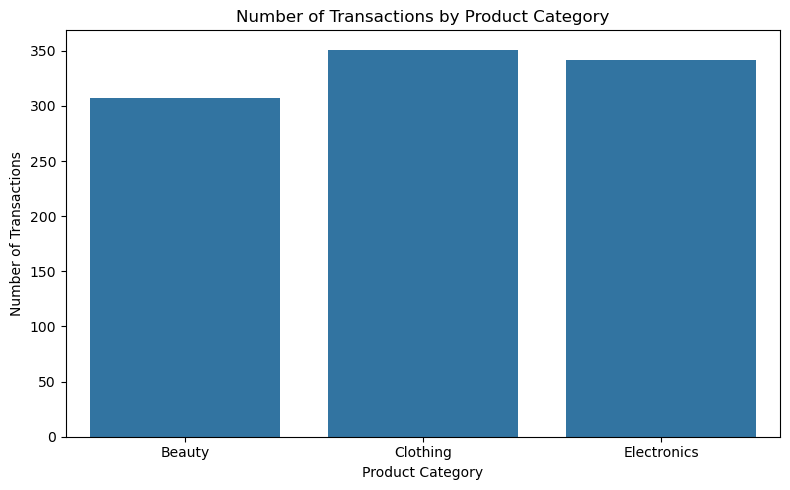

In [12]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Product Category")

plt.title("Number of Transactions by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

**Observation: Product Category-wise Transactions**

This chart compares the number of transactions across different product categories. It helps identify which categories have more customer transactions. The business can use this information to plan inventory, understand customer preferences and design suitable promotional offers.

In [13]:
print("FINAL STATISTICAL FINDINGS")

print("\nTotal Transactions:", len(df))
print("Total Revenue:", df["Total Amount"].sum())
print("Average Transaction Amount:", round(df["Total Amount"].mean(), 2))
print("Average Customer Age:", round(df["Age"].mean(), 2))
print("Total Quantity Sold:", df["Quantity"].sum())

print("\nRevenue by Product Category:")
print(df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False))

print("\nRevenue by Gender:")
print(df.groupby("Gender")["Total Amount"].sum().sort_values(ascending=False))

print("\nRevenue by Age Group:")
print(df.groupby("Age Group", observed=False)["Total Amount"].sum().sort_values(ascending=False))

FINAL STATISTICAL FINDINGS

Total Transactions: 1000
Total Revenue: 456000
Average Transaction Amount: 456.0
Average Customer Age: 41.39
Total Quantity Sold: 2514

Revenue by Product Category:
Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

Revenue by Gender:
Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64

Revenue by Age Group:
Age Group
46-55    100690
26-35     98480
36-45     91870
18-25     84550
56-64     80410
Name: Total Amount, dtype: int64


# Conclusion and Recommendations

## Conclusion

Exploratory Data Analysis (EDA) was performed on the Retail Sales Dataset using Python, Pandas, Matplotlib and Seaborn. The dataset contains 1,000 transactions and generated a total revenue of 456,000. The average transaction amount is 456, and the average customer age is 41.39 years.

The analysis shows that Electronics generated the highest revenue of 156,905, followed by Clothing at 155,580 and Beauty at 143,515. Female customers contributed 232,840 in sales, while male customers contributed 223,160. The 46–55 age group generated the highest revenue of 100,690.

The dataset was analyzed using statistical summaries, monthly and quarterly sales trends, gender-wise sales, age-group analysis, category-wise revenue, top 10 transactions, a correlation heatmap and additional visualizations.

## Actionable Recommendations

1. **Focus on Electronics:** Electronics generated the highest revenue (156,905). The business should monitor demand and maintain sufficient inventory for this category.

2. **Improve Clothing Sales:** Clothing generated 155,580, which is close to Electronics revenue. Targeted promotions may help increase sales in this category.

3. **Target the 46–55 Age Group:** This age group generated the highest revenue (100,690). The business can test targeted marketing campaigns for these customers.

4. **Understand Customer Purchasing Patterns:** Female customers contributed 232,840 in sales compared with 223,160 from male customers. The business can study purchasing preferences across both groups before designing marketing campaigns.

5. **Monitor Sales Trends:** Use monthly and quarterly sales charts to identify periods of lower sales and plan suitable promotions.

## Dataset Limitation

The dataset contains product categories but does not include individual product names. Therefore, the analysis identifies the top 10 transactions rather than the top 10 individual products.

## Final Outcome

This project demonstrates how Python-based exploratory data analysis can help summarize retail performance, understand customer purchasing patterns and support data-driven business decisions.